## 5. Building the Machine Learning Model

Import libraries and download data

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from catboost import CatBoostClassifier

In [ ]:
from pathlib import Path
import pandas as pd

processed_dir = Path("data/processed")

train_final = pd.read_csv(processed_dir / "train_final.csv")
test_final = pd.read_csv(processed_dir / "test_final.csv")

### 5.1 Preparing the data

Split the data into explanatory and target variables. The target variable for this dataset is TARGET column and the rest are explanatory variables.

In [ ]:
X = train_final.drop(columns = ['TARGET']).copy()
y = train_final['TARGET'].copy()
X_test = test_final.copy()

### 5.2 Training Model 

### 5.2 Model Definition & Validation Strategy

Three distinct model families are benchmarked under the exact same **5-Fold Stratified Cross-Validation** split (`random_state=99`) to ensure a fair comparison on imbalanced data:

* **KNN (Baseline):** Distance-based model wrapped in a `Pipeline` with `StandardScaler` to prevent data leakage across folds.
* **Random Forest:** Bagging-based tree ensemble (scale-invariant, no scaling required).
* **CatBoost:** Gradient boosting with symmetric (*oblivious*) trees, well-suited for tabular credit risk data.

In [ ]:
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15, n_jobs=-1)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=20,
        n_jobs=-1,
        random_state=42,
    ),
    "CatBoost": CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        eval_metric="AUC",
        random_seed=42,
        thread_count=-1,
        verbose=0,
    )
}

#### 5.2.1 5-Fold Cross Validation

* **CatBoost** achieved the highest performance (**0.75077 ± 0.00249 ROC-AUC**), outperforming Random Forest by **+0.0126** and the KNN baseline by **+0.0967**.
* Both tree-based ensembles show very low standard deviation across folds (`~0.002`), indicating strong stability and low variance.
* Based on these results, **CatBoost** is selected as the champion model for final test predictions.

In [ ]:
kfold = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 99)
results = []
oof_predictions = {}

for name, model in models.items():
    fold_aucs = []
    oof_preds = np.zeros(len(X))

    for train_idx, val_idx in kfold.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_tr, y_tr)
        y_pred_proba = model.predict_proba(X_val)[:, 1]

        oof_preds[val_idx] = y_pred_proba
        fold_aucs.append(roc_auc_score(y_val, y_pred_proba))

    mean_auc = np.mean(fold_aucs)
    std_auc = np.std(fold_aucs)

    oof_predictions[name] = oof_preds
    results.append({
      "Model": name,
      "Mean ROC-AUC": mean_auc,
      "Std ROC-AUC": std_auc
    })
    print(f"{name:20s} | ROC-AUC: {mean_auc:.5f} ± {std_auc:.5f}")

results_df = pd.DataFrame(results).sort_values(by = "Mean ROC-AUC", ascending = False)

display(results_df)

KNN                  | ROC-AUC: 0.65405 ± 0.00449
Random Forest        | ROC-AUC: 0.73817 ± 0.00213
CatBoost             | ROC-AUC: 0.75077 ± 0.00249


,Model,Mean ROC-AUC,Std ROC-AUC
2,CatBoost,0.750772,0.002493
1,Random Forest,0.738168,0.002130
0,KNN,0.654046,0.004491


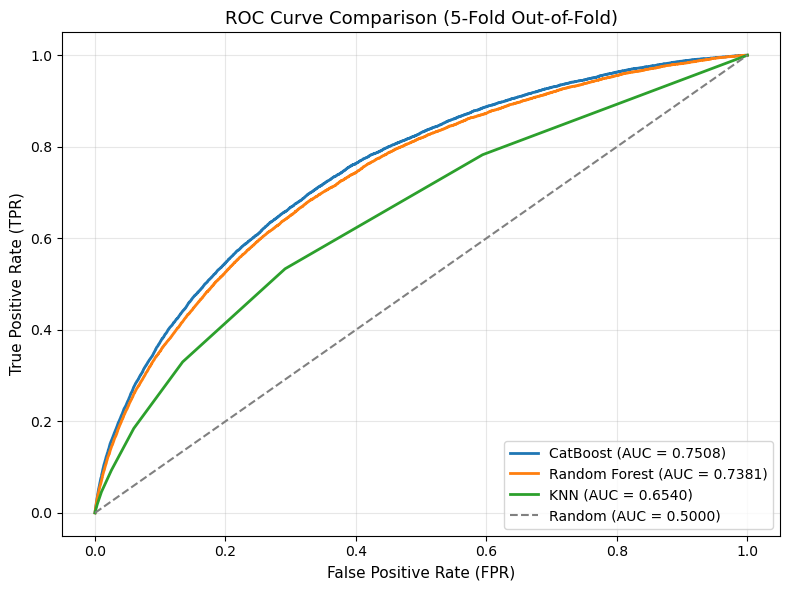

In [ ]:
plt.figure(figsize = (8,6))
for name in results_df['Model']:
    fpr, tpr, _ = roc_curve(y, oof_predictions[name])
    auc_score = roc_auc_score(y, oof_predictions[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC = 0.5000)")

plt.title("ROC Curve Comparison (5-Fold Out-of-Fold)", fontsize=13)
plt.xlabel("False Positive Rate (FPR)", fontsize=11)
plt.ylabel("True Positive Rate (TPR)", fontsize=11)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The Out-of-Fold (OOF) ROC curves confirm that **CatBoost (AUC = 0.7507)** consistently dominates both **Random Forest (AUC = 0.7381)** and **KNN (AUC = 0.6540)** across all classification thresholds, delivering a better trade-off between True Positive Rate (capturing actual defaulters) and False Positive Rate.

## 6. Creating Prediction Results

### 6.1 Out-of-Fold Ensemble Predictions
To reduce variance and leverage 100% of the training data, final test probabilities are generated by averaging the predictions of all 5 CatBoost models trained across the Stratified K-Fold splits.

In [ ]:
pred = np.zeros(len(test_final))

for train_idx, val_idx in kfold.split(X, y):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    models["CatBoost"].fit(X_tr, y_tr)
    pred += models["CatBoost"].predict_proba(test_final)[:, 1] / kfold.n_splits

In [ ]:
print(f"Predict totals: {len(pred)}")
print(f"Min: {pred.min():.4f} | Mean: {pred.mean():.4f} | Max: {pred.max():.4f}")

Predict totals: 61500
Min: 0.0010 | Mean: 0.0883 | Max: 0.7613


* All **61,500** test records were successfully scored with no missing values.
* The predicted probabilities range from `0.0010` to `0.7613`, with a mean of **0.0883** — closely aligned with the historical default rate observed in the training set (~8%), confirming well-calibrated probabilities.